# Vulkan HoloViz Ecosystem Demo (`vknumpy` + `vkpandas` + `vkshader` + `vkholoviews`)

Declarative `*` Overlay, `+` Layout, `.opts()`, GPU `datashade()`, GPU `Histogram`, `Bars`, and `Curve` on **11.84M real NYC Taxi trips**.

In [1]:
import sys, time
from pathlib import Path

_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
for _p in (_root, _root.parent / "vkshader", _root.parent / "vkpandas", _root.parent / "delightful-hertz"):
    if _p.is_dir() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import vknumpy as vnp
import vkpandas as vpd
import vkholoviews as hv

parquet = Path.home() / ".cache/hvsampledata/nyc_taxi/v2/nyc_taxi_wide.parq"
t0 = time.perf_counter()
df = vpd.read_parquet(parquet, columns=["pickup_x", "pickup_y", "fare_amount", "tip_amount", "pickup_hour"])
df["pickup_hour"] = df["pickup_hour"].astype(vnp.int32)
print(f"Loaded {len(df):,} trips into GPU vkpandas in {time.perf_counter() - t0:.2f}s")

Loaded 11,842,094 trips into GPU vkpandas in 0.33s


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


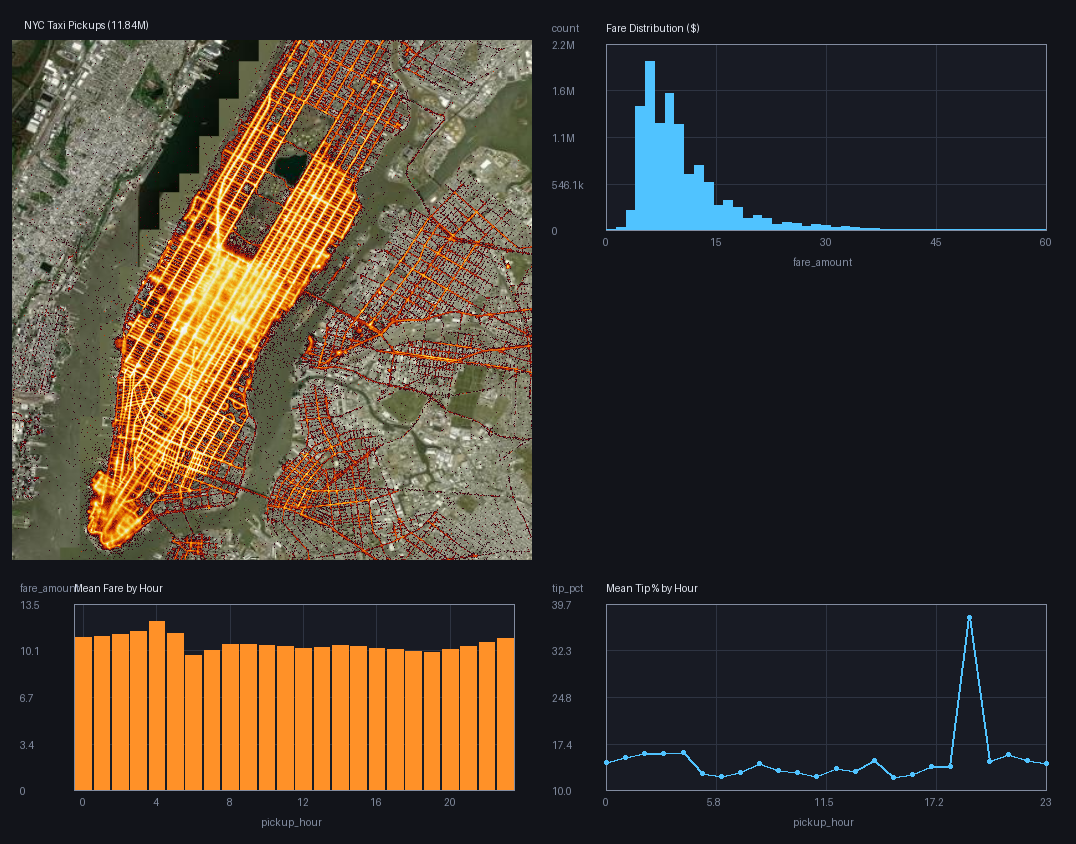

In [2]:
clean = df[df["fare_amount"] > 0.0]
clean["tip_pct"] = (clean["tip_amount"] / clean["fare_amount"]) * 100.0
by_hour = clean[["pickup_hour", "fare_amount", "tip_pct"]].groupby("pickup_hour").mean()

taxi_map = (
    hv.Tiles("esri")
    * hv.datashade(hv.Points(df, ["pickup_x", "pickup_y"]), how="eq_hist")
).opts(width=520, height=520, xlim=(-8242000, -8226000), ylim=(4968000, 4985000), title="NYC Taxi Pickups (11.84M)")

fare_hist = hv.Histogram(clean, "fare_amount", bins=45, range=(0, 60)).opts(width=520, height=260, title="Fare Distribution ($)")
hourly_fare = hv.Bars(by_hour, "pickup_hour", "fare_amount").opts(width=520, height=260, title="Mean Fare by Hour")
hourly_tip = hv.Curve(by_hour, "pickup_hour", "tip_pct").opts(width=520, height=260, title="Mean Tip % by Hour")

(taxi_map + fare_hist + hourly_fare + hourly_tip).cols(2)

In [4]:
# Live linked cross-filtering + GPU dynspread: panning/zooming the map
# recomputes the Fare & Tip histograms for ONLY the visible viewport in VRAM (~5 ms)!
linked_fare = hv.Histogram(df, "fare_amount", bins=40, range=(0, 60)).opts(width=420, height=280, title="Viewport Fare ($)")
linked_tip  = hv.Histogram(df, "tip_amount",  bins=40, range=(0, 15)).opts(width=420, height=280, title="Viewport Tip ($)")

(taxi_map.opts(width=600, height=600) + linked_fare + linked_tip).interact();